# Naive Bayes Classification — Simple Practical Notebook

**Dataset:** Wine dataset (built into scikit-learn)  
**Algorithm:** Gaussian Naive Bayes (`GaussianNB`)  
**Objective:** Predict the wine category from its measured chemical properties.

**Learning flow:** Load data → Explore → Split → Train → Predict → Evaluate → Try a test record.

No external CSV download is required.

## 1. Import the libraries

- `pandas`: show data in a table
- `load_wine`: get the standard dataset
- `train_test_split`: create training and testing sets
- `GaussianNB`: train the Naive Bayes classifier
- Evaluation functions: check how well the model predicts

In [1]:
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.datasets import load_wine
from sklearn.model_selection import train_test_split
from sklearn.naive_bayes import GaussianNB
from sklearn.metrics import accuracy_score, classification_report, ConfusionMatrixDisplay

## 2. Load the Wine dataset

The Wine dataset contains **178 records**, **13 numeric input features**, and **3 wine classes**. `X` holds the input features; `y` holds the correct class labels.

In [2]:
wine = load_wine(as_frame=True)

X = wine.data      # Input features
y = wine.target   # Correct wine class (0, 1, or 2)

In [3]:
print("Dataset shape:", X.shape)
print("Wine classes:", wine.target_names)

X.head()

Dataset shape: (178, 13)
Wine classes: ['class_0' 'class_1' 'class_2']


,alcohol,malic_acid,ash,alcalinity_of_ash,magnesium,total_phenols,flavanoids,nonflavanoid_phenols,proanthocyanins,color_intensity,hue,od280/od315_of_diluted_wines,proline
0,14.23,1.71,2.43,15.6,127.0,2.80,3.06,0.28,2.29,5.64,1.04,3.92,1065.0
1,13.20,1.78,2.14,11.2,100.0,2.65,2.76,0.26,1.28,4.38,1.05,3.40,1050.0
2,13.16,2.36,2.67,18.6,101.0,2.80,3.24,0.30,2.81,5.68,1.03,3.17,1185.0
3,14.37,1.95,2.50,16.8,113.0,3.85,3.49,0.24,2.18,7.80,0.86,3.45,1480.0
4,13.24,2.59,2.87,21.0,118.0,2.80,2.69,0.39,1.82,4.32,1.04,2.93,735.0


## 3. Understand the target column

Each numeric target value represents a wine class. The model will learn to predict one of these three classes.

In [4]:
print("Number of records in each class:")
print(y.value_counts().sort_index())

Number of records in each class:
target
0    59
1    71
2    48
Name: count, dtype: int64


## 4. Split the dataset

Use **80% for training** and **20% for testing**. `stratify=y` helps preserve the class proportions in both sets.

In [5]:
X_train, X_test, y_train, y_test = train_test_split(
    X, y,
    test_size=0.20,
    random_state=42,
    stratify=y
)

print("Training records:", len(X_train))
print("Testing records:", len(X_test))

Training records: 142
Testing records: 36


## 5. Train the Gaussian Naive Bayes model

Gaussian Naive Bayes is suitable for this example because our input features are **numeric and continuous**. It models each feature's distribution within each class using a Gaussian (bell-shaped) distribution.

`fit()` learns from the training data.

In [6]:
model = GaussianNB()
model.fit(X_train, y_train)

print("Model trained successfully")

Model trained successfully


## 6. Make predictions

`predict()` gives the predicted class for each testing record.

In [7]:
y_pred = model.predict(X_test)

results = pd.DataFrame({
    "Actual": y_test.to_numpy(),
    "Predicted": y_pred
})
results.head(10)

,Actual,Predicted
0,0,0
1,2,2
2,0,0
3,1,1
4,1,1
5,0,0
6,0,0
7,1,0
8,1,1
9,2,2


## 7. Evaluate the model

- **Accuracy:** Fraction of test predictions that are correct
- **Precision:** Of the predictions for a class, how many were correct?
- **Recall:** Of the actual records in a class, how many were found?
- **F1-score:** Balance between precision and recall

In [8]:
accuracy = accuracy_score(y_test, y_pred)
print("Test accuracy:", round(accuracy, 3))

print("\nClassification report:")
print(classification_report(y_test, y_pred, target_names=wine.target_names))

Test accuracy: 0.972

Classification report:
              precision    recall  f1-score   support

     class_0       0.92      1.00      0.96        12
     class_1       1.00      0.93      0.96        14
     class_2       1.00      1.00      1.00        10

    accuracy                           0.97        36
   macro avg       0.97      0.98      0.97        36
weighted avg       0.97      0.97      0.97        36



## 8. Display the confusion matrix

- **Rows:** actual classes
- **Columns:** predicted classes
- **Diagonal cells:** correct predictions
- **Off-diagonal cells:** incorrect predictions

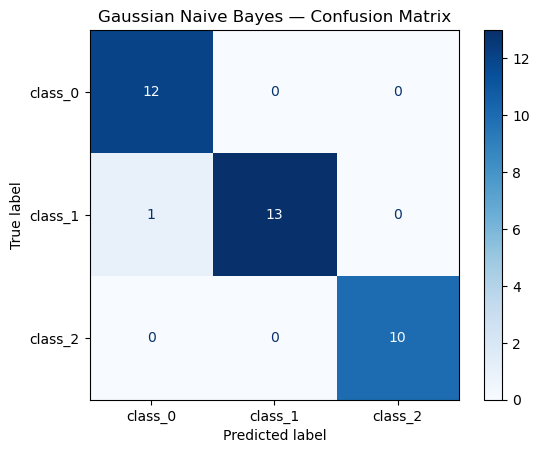

In [9]:
ConfusionMatrixDisplay.from_predictions(
    y_test,
    y_pred,
    display_labels=wine.target_names,
    cmap="Blues"
)
plt.title("Gaussian Naive Bayes — Confusion Matrix")
plt.show()

## 9. Predict one test record

Here we choose **the first row of the test set**, so we already know its true class and can compare it with the model's prediction. The `[[0]]` keeps the input in a 2D table as expected by scikit-learn.

In [10]:
one_record = X_test.iloc[[0]]

predicted_class = model.predict(one_record)[0]
actual_class = y_test.iloc[0]

print("Actual class:", wine.target_names[actual_class])
print("Predicted class:", wine.target_names[predicted_class])

Actual class: class_0
Predicted class: class_0


## 10. View predicted class probabilities

`predict_proba()` returns one estimated probability for each wine class. The model predicts the class with the highest probability.

In [11]:
probabilities = model.predict_proba(one_record)

pd.DataFrame(probabilities, columns=wine.target_names).round(3)

,class_0,class_1,class_2
0,1.0,0.0,0.0


## Key points to remember

1. **Naive Bayes** uses probability to classify records.
2. **Naive** means the model assumes features are conditionally independent given the class. This is a simplifying assumption, not necessarily true of real data.
3. **GaussianNB** is designed for continuous numeric features.
4. We trained on `X_train` and evaluated on **unseen test records** in `X_test`.
5. Feature scaling is **not essential** for GaussianNB in this example.

### Student practice

- Change `test_size=0.20` to `test_size=0.30`. How does the accuracy change?
- Look at the confusion matrix: which wine classes were confused?
- Change `one_record = X_test.iloc[[0]]` to `X_test.iloc[[1]]`. What prediction and probabilities do you get?

**Instructor note:** Naive Bayes has a simple baseline workflow; hyperparameter tuning is not necessary for this introductory notebook.